## TrOCR fine-tuning for Hindi OCR (fixed version)

Based on the original notebook by prathmeshzade (TrOCR + Niels Rogge's tutorial), cleaned up so it runs top to bottom on Kaggle.

**Before you run:** in the right sidebar click **Add Input** and add
1. the dataset **Hindi OCR synthetic line image-text pair**
2. the notebook **prathmeshzade / trocr-hi** (its output has the trained `model` and checkpoints)

By default this notebook **loads the author's trained model and evaluates it**, with no training. Set `RUN_TRAINING = True` in the settings cell to train.

## 1. Settings

In [1]:
# ===================== SETTINGS =====================
DATA_ROOT   = "/kaggle/input/hindi-ocr-synthetic-line-image-text-pair/data_80k"
IMAGE_DIR   = DATA_ROOT + "/output_images/"
CSV_PATH    = DATA_ROOT + "/data.csv"

AUTHOR_DIR  = "/kaggle/input/notebooks/prathmeshzade/trocr-hi"
MODEL_PATH  = AUTHOR_DIR + "/model"          # author's final trained model

LOAD_AUTHOR_MODEL = True    # True: use the trained model. False: start from fresh DeiT + BERT
RUN_TRAINING      = False   # True: train (or continue training)
RESUME_CKPT       = None    # e.g. AUTHOR_DIR + "/checkpoint-56000" to continue from step 56000

OUTPUT_DIR   = "/kaggle/working/trocr-hi"
MAX_LEN      = 64           # max text length in tokens
EVAL_SAMPLES = 200          # None = evaluate on the full test split
EVAL_BATCH   = 4            # lower to 2 if you get CUDA out-of-memory
EVAL_BEAMS   = 1            # 1 = greedy (low memory). Raise to 4 for slightly better accuracy

## 2. Dependencies and GPU

In [2]:
# Only jiwer is missing on Kaggle. Not upgrading transformers/datasets/pandas avoids the red
# dependency-conflict warnings, and means no session restart is needed.
!pip install -q jiwer

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cudf 23.8.0 requires cupy-cuda11x>=12.0.0, which is not installed.
dask-cuda 23.8.0 requires dask==2023.7.1, but you have dask 2024.2.0 which is incompatible.
dask-cuda 23.8.0 requires pandas<1.6.0dev0,>=1.3, but you have pandas 2.1.4 which is incompatible.
dask-cudf 23.8.0 requires dask==2023.7.1, but you have dask 2024.2.0 which is incompatible.
dask-cudf 23.8.0 requires pandas<1.6.0dev0,>=1.3, but you have pandas 2.1.4 which is incompatible.
distributed 2023.7.1 requires dask==2023.7.1, but you have dask 2024.2.0 which is incompatible.
kfp 2.5.0 requires google-cloud-storage<3,>=2.2.1, but you have google-cloud-storage 1.44.0 which is incompatible.
libpysal 4.9.2 requires packaging>=22, but you have packaging 21.3 which is incompatible.
libpysal 4.9.2 requires shapely>=2.0.1, but you have shapely 1.8.5.pos

In [3]:
import gc, os, torch

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch:", torch.__version__)
print("Using device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: no GPU. In the right sidebar set Accelerator to GPU T4 / P100.")

torch: 2.1.2
Using device: cuda
GPU: Tesla T4


In [4]:
# Fail early with a clear message if an input is missing
for p in [CSV_PATH, IMAGE_DIR]:
    assert os.path.exists(p), f"Missing: {p}. Add the dataset via Add Input."
if LOAD_AUTHOR_MODEL:
    assert os.path.isdir(MODEL_PATH), (
        f"Missing: {MODEL_PATH}\nAdd the notebook prathmeshzade/trocr-hi via Add Input, then run:\n"
        "!ls /kaggle/input/notebooks/*/*  and fix AUTHOR_DIR above."
    )
print("All input paths found.")

All input paths found.


## 3. Data

In [5]:
import pandas as pd

df = pd.read_csv(CSV_PATH)
print(df.shape)
df.head()

(80000, 5)


,image_file,text,font_size,font_file,word_count
0,1.png,गर्भनिरोध के लिए महिलाएं क्यों कराती हैं नसबंदी,51,Lohit-Devanagari.ttf,8
1,2.png,'मस्‍ज‍िद ख़ुदा का घर है तो यह ईमान वाली स्‍त्...,31,Lohit-Devanagari.ttf,17
2,3.png,"नज़रिया: गोरखपुर, नागपुर और दिल्ली के त्रिकोण ...",39,Sura-Regular.ttf,11
3,4.png,अनुच्छेद 370 के बाद क्या हो सकता है मोदी सरकार...,35,arial-unicode-ms.ttf,13
4,5.png,इराक़ में तीन अमरीकी सैनिक मारे गए,58,NotoSansDevanagari.ttf,7


In [6]:
# 90/10 split (same as the original notebook)
split = int(len(df) * 0.9)
train_df = df[:split].reset_index(drop=True)
test_df  = df[split:].reset_index(drop=True)
print(f"total: {len(df)}  train: {len(train_df)}  test: {len(test_df)}")

total: 80000  train: 72000  test: 8000


## 4. Transforms

In [7]:
from torchvision.transforms import v2, InterpolationMode
from PIL import Image
import matplotlib.pyplot as plt

train_transform = v2.Compose([
    v2.ElasticTransform(alpha=8.0, sigma=5.0, interpolation=InterpolationMode.BILINEAR, fill=0),
    v2.GaussianBlur(kernel_size=(5, 9), sigma=(0.1, 5.)),
    v2.Resize((384, 384)),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
])

eval_transform = v2.Compose([
    v2.Resize((384, 384)),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
])

I tried different data augmentation techniques, have a look at [this sheet](https://docs.google.com/spreadsheets/d/1bhlofeyP94hiB_cd41ZTV_ncHr3q00usY1mAyW-XcLM/edit?usp=sharing)

In [8]:
from torch.utils.data import Dataset


class OCRdataset(Dataset):
    def __init__(self, root_dir, df, processor, max_target_length=64, transforms=None):
        self.root_dir = root_dir
        self.df = df.reset_index(drop=True)      # reset once here, not on every item
        self.processor = processor
        self.max_target_length = max_target_length
        self.transforms = transforms

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        file_name = self.df["image_file"][idx]
        text = str(self.df["text"][idx])

        image = Image.open(self.root_dir + file_name).convert("RGB")
        pixel_values = self.transforms(image)
        if type(pixel_values) is not torch.Tensor:          # torchvision tv_tensors.Image -> plain Tensor
            pixel_values = pixel_values.as_subclass(torch.Tensor)

        tok = self.processor.tokenizer
        labels = tok(text, padding="max_length", truncation=True,
                     max_length=self.max_target_length).input_ids
        # PAD tokens must be ignored by the loss
        labels = [l if l != tok.pad_token_id else -100 for l in labels]

        return {"pixel_values": pixel_values, "labels": torch.tensor(labels)}

In [9]:
from transformers import DeiTImageProcessor, BertTokenizer, TrOCRProcessor

tokenizer = BertTokenizer.from_pretrained("bert-base-multilingual-cased")
image_processor = DeiTImageProcessor.from_pretrained("facebook/deit-base-distilled-patch16-384")
processor = TrOCRProcessor(image_processor=image_processor, tokenizer=tokenizer)

train_dataset = OCRdataset(IMAGE_DIR, train_df, processor, MAX_LEN, train_transform)
eval_dataset  = OCRdataset(IMAGE_DIR, test_df,  processor, MAX_LEN, eval_transform)
print("train examples:", len(train_dataset), " eval examples:", len(eval_dataset))

2026-10-01 03:29:26.660993: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-01 03:29:26.661125: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-01 03:29:26.840754: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

train examples: 72000  eval examples: 8000


{'pixel_values': (3, 384, 384), 'labels': (64,)}


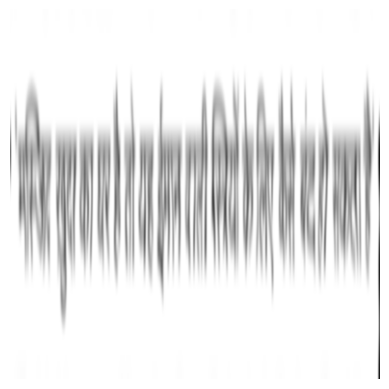

label text: ' मस्जिद ख़ुदा का घर है तो यह ईमान वाली स्त्रियों के लिए कैसे बंद हो सकता है '


In [10]:
# Sanity check: shapes, one augmented image (un-normalised for display) and its label text
enc = train_dataset[1]
print({k: tuple(v.shape) for k, v in enc.items()})

plt.imshow((enc["pixel_values"] * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0))
plt.axis("off"); plt.show()

lab = enc["labels"].clone()
lab[lab == -100] = processor.tokenizer.pad_token_id
print("label text:", processor.tokenizer.decode(lab, skip_special_tokens=True))

## 5. Model

In [11]:
from transformers import VisionEncoderDecoderModel

if LOAD_AUTHOR_MODEL:
    # the author's fine-tuned model (already trained)
    model = VisionEncoderDecoderModel.from_pretrained(MODEL_PATH)
    print("Loaded trained model from", MODEL_PATH)
else:
    # fresh start: encoder = DeiT, decoder = multilingual BERT.
    # The cross-attention layers are randomly initialised (the long red warning is expected).
    model = VisionEncoderDecoderModel.from_encoder_decoder_pretrained(
        "facebook/deit-base-distilled-patch16-384", "bert-base-multilingual-cased"
    )
    print("Built a new model from DeiT + BERT")

tok = processor.tokenizer

# special tokens
model.config.decoder_start_token_id = tok.cls_token_id
model.config.pad_token_id = tok.pad_token_id
model.config.eos_token_id = tok.sep_token_id
model.config.vocab_size = model.config.decoder.vocab_size

# generation settings (on generation_config, not on model.config, so saving the model does not fail)
gen = model.generation_config
gen.decoder_start_token_id = tok.cls_token_id
gen.pad_token_id = tok.pad_token_id
gen.eos_token_id = tok.sep_token_id
gen.max_length = MAX_LEN
gen.num_beams = 4
gen.early_stopping = True
gen.no_repeat_ngram_size = 3
gen.length_penalty = 2.0

model.to(device)
print("decoder_start_token_id:", model.config.decoder_start_token_id)

Loaded trained model from /kaggle/input/notebooks/prathmeshzade/trocr-hi/model
decoder_start_token_id: 101


## 6. Metrics

In [12]:
import numpy as np
import jiwer


def compute_metrics(pred):
    label_ids = np.array(pred.label_ids)
    pred_ids = np.array(pred.predictions)
    if pred_ids.ndim == 3:                                   # logits instead of token ids
        pred_ids = pred_ids.argmax(-1)

    pad = processor.tokenizer.pad_token_id
    label_ids = np.where(label_ids == -100, pad, label_ids)
    pred_ids = np.where(pred_ids == -100, pad, pred_ids)

    pred_str = [s.strip() for s in processor.batch_decode(pred_ids, skip_special_tokens=True)]
    label_str = [s.strip() for s in processor.batch_decode(label_ids, skip_special_tokens=True)]

    # jiwer raises on empty references, so drop them
    pairs = [(r, p) for r, p in zip(label_str, pred_str) if len(r) > 0]
    refs = [r for r, _ in pairs]
    hyps = [p for _, p in pairs]

    cer = jiwer.cer(refs, hyps)
    wer = jiwer.wer(refs, hyps)
    accuracy = sum(r == p for r, p in pairs) / max(len(pairs), 1)

    return {"accuracy": accuracy, "cer": cer, "wer": wer}

## 7. Trainer

In [13]:
import inspect
from transformers import Seq2SeqTrainer, Seq2SeqTrainingArguments, default_data_collator

# keep working across transformers versions
arg_names = inspect.signature(Seq2SeqTrainingArguments.__init__).parameters
eval_key = "eval_strategy" if "eval_strategy" in arg_names else "evaluation_strategy"
trainer_names = inspect.signature(Seq2SeqTrainer.__init__).parameters
tok_key = "processing_class" if "processing_class" in trainer_names else "tokenizer"

use_fp16 = torch.cuda.is_available()

training_args = Seq2SeqTrainingArguments(
    output_dir=OUTPUT_DIR,
    predict_with_generate=True,
    generation_max_length=MAX_LEN,
    generation_num_beams=EVAL_BEAMS,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=EVAL_BATCH,
    eval_accumulation_steps=1,          # move predictions to CPU each step (saves GPU memory)
    num_train_epochs=7,
    learning_rate=4e-5,
    fp16=use_fp16,
    fp16_full_eval=use_fp16,
    report_to="none",                   # no wandb login needed
    logging_strategy="steps",
    logging_steps=50,
    save_strategy="steps",
    save_steps=8000,
    save_total_limit=2,                 # keep only the 2 newest checkpoints (disk limit)
    eval_steps=8000,
    **{eval_key: "steps"},
)

trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    compute_metrics=compute_metrics,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    data_collator=default_data_collator,
    **{tok_key: processor.tokenizer},
)
print("Trainer ready.")

Trainer ready.


## 8. Evaluate (CER / WER / accuracy)

In [14]:
# Training is optional. Set RUN_TRAINING = True in the settings cell to use it.
if RUN_TRAINING:
    if RESUME_CKPT:
        assert os.path.isdir(RESUME_CKPT), f"Checkpoint not found: {RESUME_CKPT}"
        trainer.train(resume_from_checkpoint=RESUME_CKPT)
    else:
        trainer.train()
    trainer.save_model(OUTPUT_DIR + "/model")
    processor.save_pretrained(OUTPUT_DIR + "/model")
    print("Saved to", OUTPUT_DIR + "/model")
else:
    print("Skipping training (RUN_TRAINING = False).")

Skipping training (RUN_TRAINING = False).


In [15]:
from torch.utils.data import Subset

gc.collect()
torch.cuda.empty_cache()

ds = eval_dataset if EVAL_SAMPLES is None else Subset(eval_dataset, range(min(EVAL_SAMPLES, len(eval_dataset))))
metrics = trainer.evaluate(eval_dataset=ds)

print("CER:      ", round(metrics["eval_cer"], 4))
print("WER:      ", round(metrics["eval_wer"], 4))
print("Accuracy: ", round(metrics["eval_accuracy"], 4))
print("Loss:     ", round(metrics["eval_loss"], 4))

/opt/conda/lib/python3.10/site-packages/transformers/generation/configuration_utils.py:453: UserWarning: `num_beams` is set to 1. However, `early_stopping` is set to `True` -- this flag is only used in beam-based generation modes. You should set `num_beams>1` or unset `early_stopping`.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/transformers/generation/configuration_utils.py:472: UserWarning: `num_beams` is set to 1. However, `length_penalty` is set to `2.0` -- this flag is only used in beam-based generation modes. You should set `num_beams>1` or unset `length_penalty`.
  warnings.warn(
We strongly recommend passing in an `attention_mask` since your input_ids may be padded. See https://huggingface.co/docs/transformers/troubleshooting#incorrect-output-when-padding-tokens-arent-masked.
/opt/conda/lib/python3.10/site-packages/torch/nn/parallel/_functions.py:68: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and r

CER:       0.0053
WER:       0.0224
Accuracy:  0.89
Loss:      0.2598


## 9. Inference

In [16]:
model.eval()


@torch.no_grad()
def ocr(image, num_beams=4):
    """Run OCR on a PIL image and return the text."""
    image = image.convert("RGB")
    pixel_values = eval_transform(image).as_subclass(torch.Tensor).unsqueeze(0).to(device)
    ids = model.generate(pixel_values, max_length=MAX_LEN, num_beams=num_beams)
    return processor.batch_decode(ids, skip_special_tokens=True)[0]

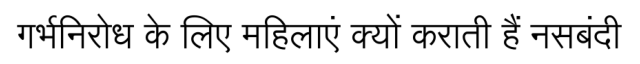

Image:      /kaggle/input/hindi-ocr-synthetic-line-image-text-pair/data_80k/output_images/1.png
Predicted:  गर्भनिरोध के लिए महिलाएं क्यों कराती हैं नसबंदी
Truth:      गर्भनिरोध के लिए महिलाएं क्यों कराती हैं नसबंदी
------------------------------------------------------------


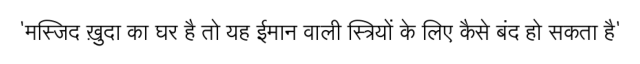

Image:      /kaggle/input/hindi-ocr-synthetic-line-image-text-pair/data_80k/output_images/2.png
Predicted:  ' मस्जिद ख़ुदा का घर है तो यह ईमान वाली स्त्रियों के लिए कैसे बंद हो सकता है '
Truth:      'मस्‍ज‍िद ख़ुदा का घर है तो यह ईमान वाली स्‍त्र‍ियों के लिए कैसे बंद हो सकता है'
------------------------------------------------------------


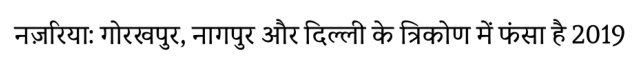

Image:      /kaggle/input/hindi-ocr-synthetic-line-image-text-pair/data_80k/output_images/3.png
Predicted:  नज़रिया : गोरखपुर, नागपुर और दिल्ली के त्रिकोण में फंसा है 2019
Truth:      नज़रिया: गोरखपुर, नागपुर और दिल्ली के त्रिकोण में फंसा है 2019
------------------------------------------------------------


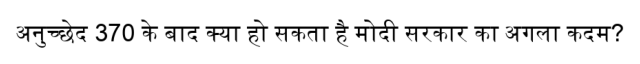

Image:      /kaggle/input/hindi-ocr-synthetic-line-image-text-pair/data_80k/output_images/4.png
Predicted:  अनुच्छेद 370 के बाद क्या हो सकता है मोदी सरकार का अगला कदम?
Truth:      अनुच्छेद 370 के बाद क्या हो सकता है मोदी सरकार का अगला कदम?
------------------------------------------------------------


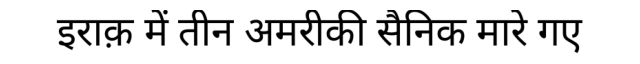

Image:      /kaggle/input/hindi-ocr-synthetic-line-image-text-pair/data_80k/output_images/5.png
Predicted:  इराक़ में तीन अमरीकी सैनिक मारे गए
Truth:      इराक़ में तीन अमरीकी सैनिक मारे गए
------------------------------------------------------------


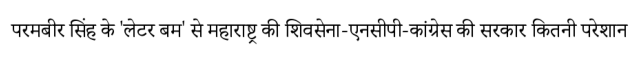

Image:      /kaggle/input/hindi-ocr-synthetic-line-image-text-pair/data_80k/output_images/6.png
Predicted:  परमबीर सिंह के'लेटर बम'से महाराष्ट्र की गिवसेना - एनसीपी - कांग्रेस की सरकार कितनी परेशान
Truth:      परमबीर सिंह के 'लेटर बम' से महाराष्ट्र की शिवसेना-एनसीपी-कांग्रेस की सरकार कितनी परेशान
------------------------------------------------------------


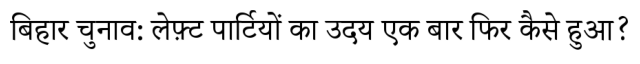

Image:      /kaggle/input/hindi-ocr-synthetic-line-image-text-pair/data_80k/output_images/7.png
Predicted:  बिहार चुनाव : लेफ़्ट पार्टियों का उदय एक बार फिर कैसे हुआ?
Truth:      बिहार चुनाव: लेफ़्ट पार्टियों का उदय एक बार फिर कैसे हुआ?
------------------------------------------------------------


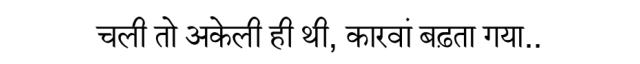

Image:      /kaggle/input/hindi-ocr-synthetic-line-image-text-pair/data_80k/output_images/8.png
Predicted:  चली तो अकेली ही थी, कारवां बढ़ता गया..
Truth:      चली तो अकेली ही थी, कारवां बढ़ता गया..
------------------------------------------------------------


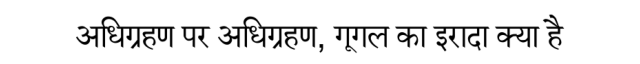

Image:      /kaggle/input/hindi-ocr-synthetic-line-image-text-pair/data_80k/output_images/9.png
Predicted:  अधिग्रहण पर अभिग्रहण, गूगल का इरादा क्या है
Truth:      अधिग्रहण पर अधिग्रहण, गूगल का इरादा क्या है
------------------------------------------------------------


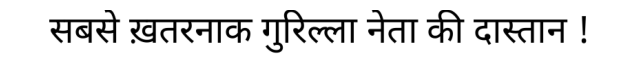

Image:      /kaggle/input/hindi-ocr-synthetic-line-image-text-pair/data_80k/output_images/10.png
Predicted:  सबसे ख़तरनाक गुरिल्ला नेता की दास्तान!
Truth:      सबसे ख़तरनाक गुरिल्ला नेता की दास्तान !
------------------------------------------------------------


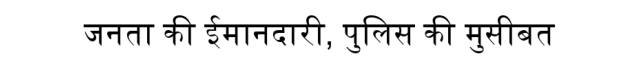

Image:      /kaggle/input/hindi-ocr-synthetic-line-image-text-pair/data_80k/output_images/11.png
Predicted:  जनता की ईमानदारी, पुलिस की मुसीबत
Truth:      जनता की ईमानदारी, पुलिस की मुसीबत
------------------------------------------------------------


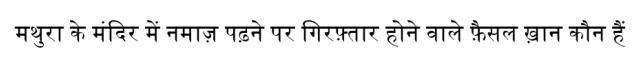

Image:      /kaggle/input/hindi-ocr-synthetic-line-image-text-pair/data_80k/output_images/12.png
Predicted:  मथुरा के मंदिर में नमाज़ पढ़ने पर गिरफ़्तार होने वाले फ़ैसल ख़ान कौन हैं
Truth:      मथुरा के मंदिर में नमाज़ पढ़ने पर गिरफ़्तार होने वाले फ़ैसल ख़ान कौन हैं
------------------------------------------------------------


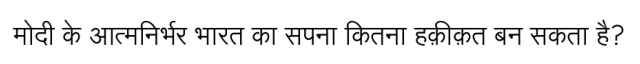

Image:      /kaggle/input/hindi-ocr-synthetic-line-image-text-pair/data_80k/output_images/13.png
Predicted:  मोदी के आत्मनिर्भर भारत का सपना कितना हक़ीक़त बन सकता है?
Truth:      मोदी के आत्मनिर्भर भारत का सपना कितना हक़ीक़त बन सकता है?
------------------------------------------------------------


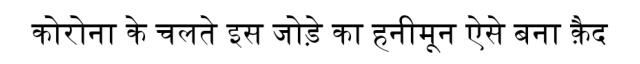

Image:      /kaggle/input/hindi-ocr-synthetic-line-image-text-pair/data_80k/output_images/14.png
Predicted:  कोरोना के चलते इस जोड़े का हनीमून ऐसे बना क़ैद
Truth:      कोरोना के चलते इस जोड़े का हनीमून ऐसे बना क़ैद
------------------------------------------------------------


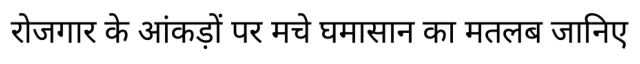

Image:      /kaggle/input/hindi-ocr-synthetic-line-image-text-pair/data_80k/output_images/15.png
Predicted:  रोजगार के आंकड़ों पर मचे घमासान का मतलब जानिए
Truth:      रोजगार के आंकड़ों पर मचे घमासान का मतलब जानिए
------------------------------------------------------------


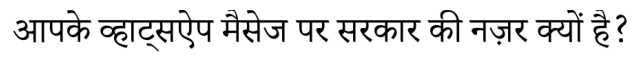

Image:      /kaggle/input/hindi-ocr-synthetic-line-image-text-pair/data_80k/output_images/16.png
Predicted:  आपके व्हाट्सऐप मैसेज पर सरकार की नज़र क्यों है?
Truth:      आपके व्हाट्सऐप मैसेज पर सरकार की नज़र क्यों है?
------------------------------------------------------------


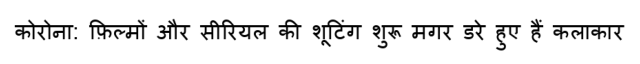

Image:      /kaggle/input/hindi-ocr-synthetic-line-image-text-pair/data_80k/output_images/17.png
Predicted:  कोरोना : फ़िल्मों और सीरियल की शूटिंग शुरू मगर डरे हुए हैं कलाकार
Truth:      कोरोना: फ़िल्मों और सीरियल की शूटिंग शुरू मगर डरे हुए हैं कलाकार
------------------------------------------------------------


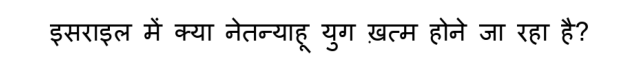

Image:      /kaggle/input/hindi-ocr-synthetic-line-image-text-pair/data_80k/output_images/18.png
Predicted:  इसराइल में क्या नेतन्याहू युग ख़त्म होने जा रहा है?
Truth:      इसराइल में क्या नेतन्याहू युग ख़त्म होने जा रहा है?
------------------------------------------------------------


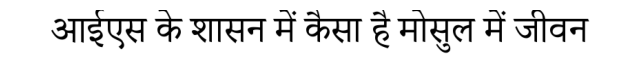

Image:      /kaggle/input/hindi-ocr-synthetic-line-image-text-pair/data_80k/output_images/19.png
Predicted:  आईएस के शासन में कैसा है मोसुल में जीवन
Truth:      आईएस के शासन में कैसा है मोसुल में जीवन
------------------------------------------------------------


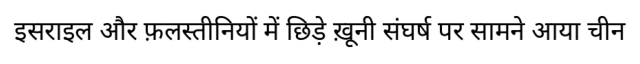

Image:      /kaggle/input/hindi-ocr-synthetic-line-image-text-pair/data_80k/output_images/20.png
Predicted:  इसराइल और फ़लस्तीनियों में छिड़े ख़ूनी संघर्ष पर सामने आया चीन
Truth:      इसराइल और फ़लस्तीनियों में छिड़े ख़ूनी संघर्ष पर सामने आया चीन
------------------------------------------------------------


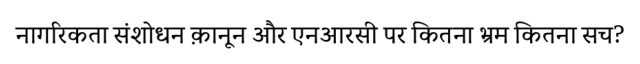

Image:      /kaggle/input/hindi-ocr-synthetic-line-image-text-pair/data_80k/output_images/21.png
Predicted:  नागरिकता संशोधन क़ानून और एनआरसी पर कितना भ्रम कतना सच?
Truth:      नागरिकता संशोधन क़ानून और एनआरसी पर कितना भ्रम कितना सच?
------------------------------------------------------------


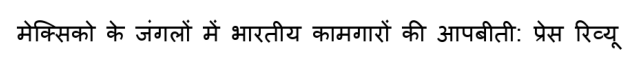

Image:      /kaggle/input/hindi-ocr-synthetic-line-image-text-pair/data_80k/output_images/22.png
Predicted:  मेक्सिको के जंगलों में भारतीय कामगारों की आपबीती : प्रेस रिव्यू
Truth:      मेक्सिको के जंगलों में भारतीय कामगारों की आपबीती: प्रेस रिव्यू
------------------------------------------------------------


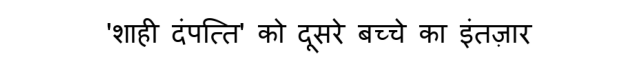

Image:      /kaggle/input/hindi-ocr-synthetic-line-image-text-pair/data_80k/output_images/23.png
Predicted:  ' शाही दंपत्ति'को दूसरे बच्चे का इंतज़ार
Truth:      'शाही दंपत्ति' को दूसरे बच्चे का इंतज़ार
------------------------------------------------------------


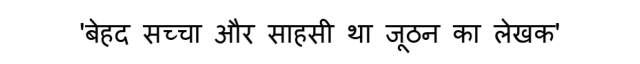

Image:      /kaggle/input/hindi-ocr-synthetic-line-image-text-pair/data_80k/output_images/24.png
Predicted:  ' बेहद सच्चा और साहसी था जूठन का लेखक '
Truth:      'बेहद सच्चा और साहसी था जूठन का लेखक'
------------------------------------------------------------


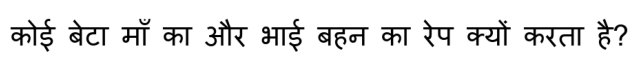

Image:      /kaggle/input/hindi-ocr-synthetic-line-image-text-pair/data_80k/output_images/25.png
Predicted:  कोई बेटा माँ का और भाई बहन का रेप क्यों करता है?
Truth:      कोई बेटा माँ का और भाई बहन का रेप क्यों करता है?
------------------------------------------------------------


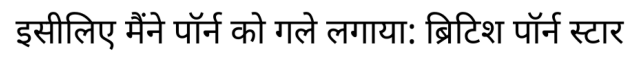

Image:      /kaggle/input/hindi-ocr-synthetic-line-image-text-pair/data_80k/output_images/26.png
Predicted:  इसीलिए मैंने पॉर्न को गले लगाया : ब्रिटिश पॉन्न स्टार
Truth:      इसीलिए मैंने पॉर्न को गले लगाया: ब्रिटिश पॉर्न स्टार
------------------------------------------------------------


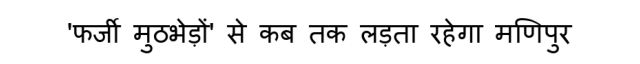

Image:      /kaggle/input/hindi-ocr-synthetic-line-image-text-pair/data_80k/output_images/27.png
Predicted:  ' फर्जी मुठभेड़ों'से कब तक लड़ता रहेगा मणिपुर
Truth:      'फर्जी मुठभेड़ों' से कब तक लड़ता रहेगा मणिपुर
------------------------------------------------------------


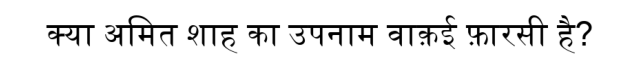

Image:      /kaggle/input/hindi-ocr-synthetic-line-image-text-pair/data_80k/output_images/28.png
Predicted:  क्या अमित शाह का उपनाम वाक़ई फ़ारसी है?
Truth:      क्या अमित शाह का उपनाम वाक़ई फ़ारसी है?
------------------------------------------------------------


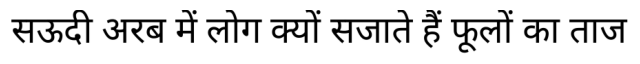

Image:      /kaggle/input/hindi-ocr-synthetic-line-image-text-pair/data_80k/output_images/29.png
Predicted:  सऊदी अरब में लोग क्यों सजाते हैं फूलों का ताज
Truth:      सऊदी अरब में लोग क्यों सजाते हैं फूलों का ताज
------------------------------------------------------------


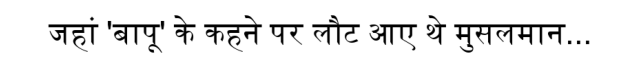

Image:      /kaggle/input/hindi-ocr-synthetic-line-image-text-pair/data_80k/output_images/30.png
Predicted:  जहां'बापू'के कहने पर लौट आए थे मुसलमान...
Truth:      जहां 'बापू' के कहने पर लौट आए थे मुसलमान...
------------------------------------------------------------


In [17]:
# first 30 training images: image, prediction and ground truth
for i in range(1, 31):
    path = f"{IMAGE_DIR}{i}.png"
    if not os.path.exists(path):
        continue
    img = Image.open(path).convert("RGB")
    plt.figure(figsize=(8, 2)); plt.imshow(img); plt.axis("off"); plt.show()
    print("Image:     ", path)
    print("Predicted: ", ocr(img))
    row = df[df["image_file"] == f"{i}.png"]
    if len(row):
        print("Truth:     ", row["text"].iloc[0])
    print("-" * 60)